# 03 · Évaluation finale, décision et ROI
**Prérequis :** exécuter 02 une première fois (les sorties nécessaires sont également fournies). Ce notebook reconstruit le pipeline gelé et le réajuste sur le train uniquement, sans nouvelle sélection ni nouveau réglage. Il ouvre le test pour l'évaluation finale et réalise ensuite des diagnostics descriptifs, sans modifier le choix.

Les montants sont des **hypothèses de scénario**, pas des économies constatées. Le ROI inclut 55 000 € de coût de projet en année 1.

## Guide de lecture
**Question :** le choix gelé fonctionne-t-il sur le test, et dans quelles conditions serait-il rentable ?

**Exécution :** le fichier `results/selection.json`, inclus dans le projet et produit par 02, fixe le modèle, les paramètres et le seuil. Le pipeline est reconstruit et ajusté uniquement sur le train ; aucun fichier modèle binaire n'est requis et aucun nouveau réglage n'est réalisé.

**À savoir à l'oral :** le gain brut, le gain net après coût du projet et le ROI sont trois quantités différentes. Une performance sur des données synthétiques n'est pas une preuve d'économies industrielles.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src/project.py').exists() else Path.cwd().parent
assert (ROOT / 'src/project.py').exists(), 'Ouvrir depuis la racine du projet ou notebooks/.'
sys.path.insert(0, str(ROOT / 'src'))
from project import *
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top':False, 'axes.spines.right':False, 'figure.dpi':110})
pd.set_option('display.max_columns', 25)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches='tight')
    plt.show()

import joblib
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.inspection import permutation_importance
assert (RESULTS/'selection.json').exists(), 'Exécuter 02_modelisation.ipynb au préalable.'
selection=json.loads((RESULTS/'selection.json').read_text())
df=load_data(); train_idx,test_idx=split_indices(df)
model=rebuild_selected_pipeline(selection)
model.fit(df.iloc[train_idx][FEATURES],df.iloc[train_idx].machine_failure)
X_test=df.iloc[test_idx][FEATURES].copy()
y_test=df.iloc[test_idx].machine_failure.copy()
threshold=selection['threshold']
p=model.predict_proba(X_test)[:,1]
pred=p>=threshold
score=metrics(y_test,p,threshold)
(RESULTS/'test_metrics.json').write_text(json.dumps(score,indent=2),encoding='utf-8')
display(pd.DataFrame([{'model':selection['model'],'threshold':threshold,**score}]))
print(f"Objectif rappel et précision atteint sur test : {score['recall'] >= .8 and score['precision'] >= 1/3}")
print(f"Coût sans alerte : {y_test.sum()*3000:,.0f} € ; coût avec alertes : {score['cost']:,.0f} €.")


Objectif rappel et précision atteint sur test : True
Coût sans alerte : 204,000 € ; coût avec alertes : 60,100 €.


,model,threshold,tn,fp,fn,tp,recall,precision,f1,ap,accuracy,cost
0,Random Forest,0.17,1908,24,9,59,0.867647,0.710843,0.781457,0.886043,0.9835,60100.0


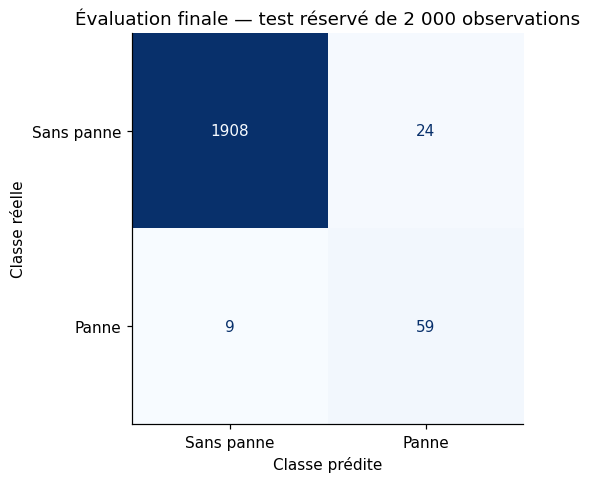

**Lecture :** 59 pannes détectées, 9 manquées et 24 fausses alertes. Le rappel vaut 86.8% et la précision 71.1%.

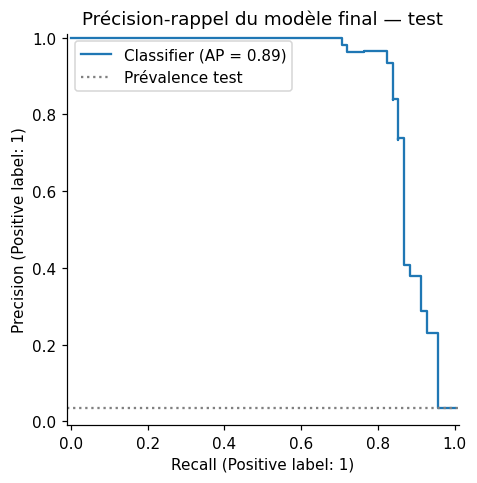

In [2]:
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['Sans panne','Panne'],cmap='Blues',colorbar=False)
plt.title('Évaluation finale — test réservé de 2 000 observations')
plt.xlabel('Classe prédite'); plt.ylabel('Classe réelle')
savefig('05_confusion.png')
display(Markdown(f"**Lecture :** {score['tp']} pannes détectées, {score['fn']} manquées et {score['fp']} fausses alertes. Le rappel vaut {score['recall']:.1%} et la précision {score['precision']:.1%}."))
PrecisionRecallDisplay.from_predictions(y_test,p)
plt.axhline(y_test.mean(),linestyle=':',color='gray',label='Prévalence test')
plt.title('Précision-rappel du modèle final — test'); plt.legend()
savefig('06_precision_rappel.png')

**Lecture :** la courbe précision-rappel décrit le classement du modèle sur le test. Elle n'est pas utilisée pour changer le seuil. La référence horizontale est la prévalence. Une précision élevée signifie moins d'inspections inutiles ; un rappel élevé signifie moins de pannes manquées.

In [3]:
# Incertitude d'échantillonnage, modèle fixe : bootstrap des couples cible/score.
rng=np.random.default_rng(SEED)
boot=[]
for _ in range(1000):
    idx=rng.integers(0,len(y_test),len(y_test))
    m=metrics(y_test.to_numpy()[idx],p[idx],threshold)
    boot.append([m['recall'],m['precision'],m['ap']])
ci=pd.DataFrame(np.quantile(boot,[.025,.975],axis=0),index=['borne 2,5 %','borne 97,5 %'],columns=['recall','precision','ap'])
display(ci.round(3)); ci.to_csv(RESULTS/'test_bootstrap.csv')

,recall,precision,ap
"borne 2,5 %",0.774,0.609,0.810
"borne 97,5 %",0.947,0.802,0.947


Ces intervalles bootstrap décrivent l'incertitude du petit échantillon test, sous hypothèse de lignes indépendantes. Ils n'intègrent ni l'incertitude de réentraînement, ni la dépendance entre cycles, ni le changement de domaine industriel.

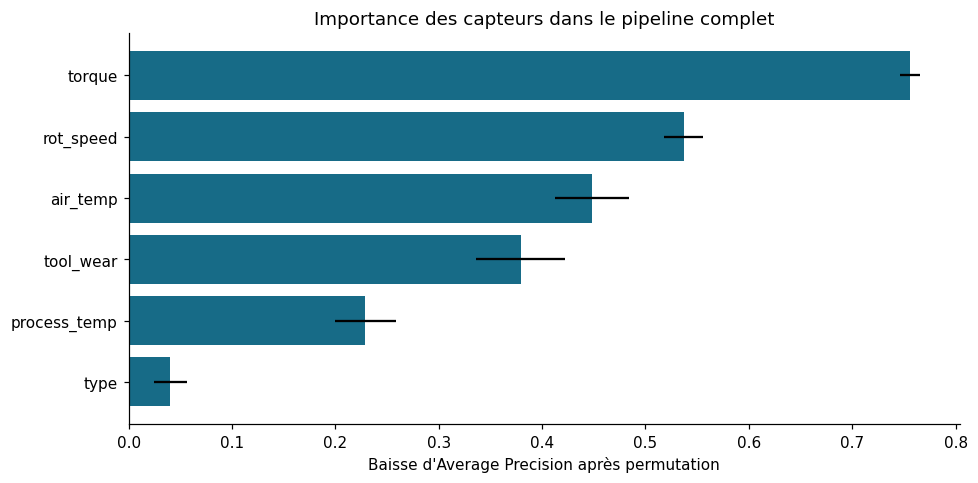

**Lecture :** les variables les plus influentes dans cette exécution sont torque, rot_speed, air_temp. Leur permutation recalcule aussi les variables physiques dérivées. Ces importances ne sont pas causales et peuvent être partagées entre capteurs corrélés.

,type,air_temp,process_temp,rot_speed,torque,tool_wear,udi,target,score,prediction,resultat
9174,L,297.8,308.9,1871,25.6,200,9175,1,0.00,0,FN
2671,M,299.7,309.3,1399,41.9,221,2672,1,0.02,0,FN
3695,L,302.2,311.3,1530,37.3,207,3696,1,0.06,0,FN
7087,L,300.6,310.3,1648,30.5,217,7088,1,0.05,0,FN
2941,M,300.7,309.6,1996,19.8,203,2942,1,0.05,0,FN
9015,L,297.2,308.1,1431,49.7,210,9016,1,0.03,0,FN
7849,M,300.3,311.7,1374,47.9,222,7850,1,0.02,0,FN
8506,L,298.4,309.6,1710,27.3,163,8507,1,0.00,0,FN
1996,M,298.4,308.0,1416,38.2,198,1997,1,0.00,0,FN


,type,air_temp,process_temp,rot_speed,torque,tool_wear,udi,target,score,prediction,resultat
3794,M,302.2,310.8,1356,48.3,36,3795,0,0.73,1,FP
4231,L,302.2,310.8,1340,47.8,54,4232,0,0.71,1,FP
7086,L,300.6,310.4,2514,13.4,215,7087,0,0.37,1,FP
592,H,297.5,309.5,1668,27.9,240,593,0,0.35,1,FP
3856,M,302.4,311.2,1330,58.6,201,3857,0,0.31,1,FP
5988,H,300.7,310.8,1296,58.2,204,5989,0,0.31,1,FP
4379,M,301.8,309.5,1732,30.1,220,4380,0,0.30,1,FP
6612,L,301.6,310.6,1222,70.0,62,6613,0,0.30,1,FP
585,L,297.6,309.5,2001,20.5,220,586,0,0.27,1,FP
5391,L,302.7,312.2,1572,34.4,228,5392,0,0.24,1,FP


,air_temp,process_temp,rot_speed,torque,tool_wear
resultat,,,,,
FN,299.70,309.6,1530.0,37.3,207.0
FP,300.75,310.5,1571.0,35.3,216.0
TN,300.00,310.1,1507.0,39.9,109.0
TP,301.90,310.4,1353.0,55.1,148.0


In [4]:
importance=permutation_importance(model,X_test,y_test,scoring='average_precision',n_repeats=10,random_state=SEED,n_jobs=2)
imp=pd.DataFrame({'variable':FEATURES,'AP_perdue':importance.importances_mean,'ecart_type':importance.importances_std}).sort_values('AP_perdue')
imp.to_csv(RESULTS/'importance.csv',index=False)
plt.barh(imp.variable,imp.AP_perdue,xerr=imp.ecart_type,color='#176B87')
plt.xlabel("Baisse d'Average Precision après permutation"); plt.title('Importance des capteurs dans le pipeline complet')
savefig('07_importance.png')
display(Markdown('**Lecture :** les variables les plus influentes dans cette exécution sont '+', '.join(imp.tail(3).iloc[::-1].variable)+'. Leur permutation recalcule aussi les variables physiques dérivées. Ces importances ne sont pas causales et peuvent être partagées entre capteurs corrélés.'))
errors=X_test.copy(); errors['udi']=df.iloc[test_idx].udi; errors['target']=y_test; errors['score']=p; errors['prediction']=pred.astype(int)
errors['resultat']=np.select([(y_test==1)&pred,(y_test==1)&~pred,(y_test==0)&pred],['TP','FN','FP'],default='TN')
errors.to_csv(RESULTS/'test_predictions.csv',index=False)
display(errors[errors.resultat=='FN'].head(10))
display(errors[errors.resultat=='FP'].sort_values('score',ascending=False).head(10))
display(errors.groupby('resultat')[RAW_NUM].median().round(2))

**Analyse des erreurs :** les tables montrent les pannes manquées et les alertes injustifiées, avec les capteurs correspondants. Le recouvrement des profils, les modes aléatoires et les limites du modèle peuvent expliquer ces erreurs ; aucune cause certaine n'est déduite de ces seules lignes. Les analyser ne donne pas le droit d'ajuster le modèle sur ce test. Un prochain modèle nécessiterait une nouvelle validation indépendante.

## ROI et analyse de sensibilité
Volume hypothétique : **5 000 cycles/an**. Prévalence projetée : 3,39 % du fichier complet, une hypothèse à confirmer au pilote. Coût projet : développement 30 000 €, déploiement 15 000 €, exploitation année 1 10 000 € = **55 000 €**.

`TP/an = cycles × prévalence × rappel` ; `FN/an = pannes/an − TP/an` ; `FP/an = TP/an × (1/précision − 1)`.

`Gain brut = coût sans modèle − coût avec modèle` ; `gain net = gain brut − 55 000` ; `ROI = gain net / 55 000` ; `retour = 12 × 55 000 / gain brut` si le gain est positif.

Le scénario pessimiste diminue rappel et précision de 20 % et le coût panne à 1 500 €. Un scénario additionnel suppose que seules 70 % des vraies alertes évitent effectivement la panne. Le seuil reste gelé : on mesure sa robustesse, sans l'optimiser a posteriori.

Seuil de rentabilité complet année 1 : 935 €/panne évitée.
Seuil opérationnel seul, hors projet : 561 €/panne.
Contrôles métier : {'rappel_test': True, 'precision_test': True, 'gain_net_pessimiste': np.True_}


,scenario,recall,precision,failure_cost,gain,net_gain,roi_pct,payback_months
0,Pessimiste,0.69,0.57,1500,104267.43,49267.43,89.58,6.33
1,Central,0.87,0.71,3000,358691.91,303691.91,552.17,1.84
2,Optimiste,0.87,0.71,4500,579291.18,524291.18,953.26,1.14
3,Défavorable — panne 500 €,0.87,0.71,500,-8973.53,-63973.53,-116.32,NaN
4,Intervention efficace à 70 %,0.87,0.71,3000,226332.35,171332.35,311.51,2.92


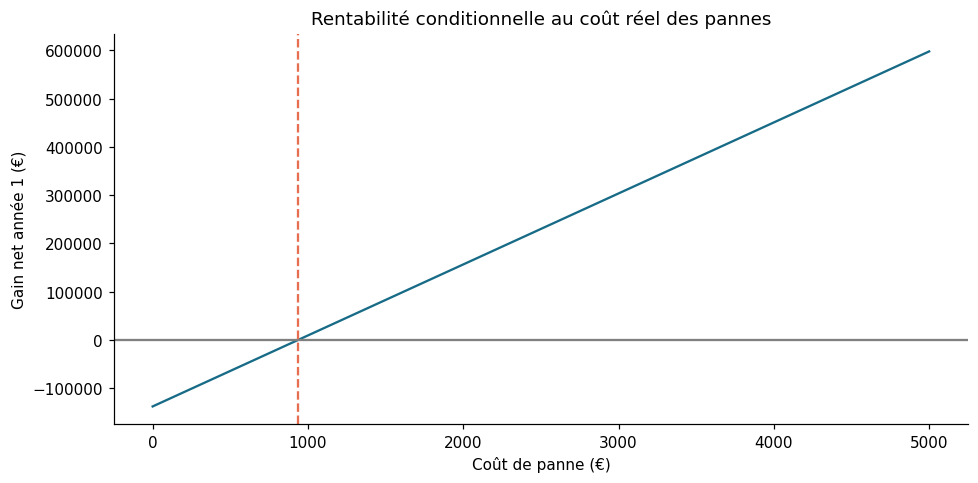

In [5]:
prevalence=float(df.machine_failure.mean())
r,pr=score['recall'],score['precision']
scenarios=pd.DataFrame([
annual_scenario('Pessimiste',prevalence,.8*r,.8*pr,1500),
annual_scenario('Central',prevalence,r,pr,3000),
annual_scenario('Optimiste',prevalence,r,pr,4500),
annual_scenario('Défavorable — panne 500 €',prevalence,r,pr,500),
annual_scenario('Intervention efficace à 70 %',prevalence,r,pr,3000,effectiveness=.7)])
display(scenarios[['scenario','recall','precision','failure_cost','gain','net_gain','roi_pct','payback_months']].round(2)); scenarios.to_csv(RESULTS/'roi_scenarios.csv',index=False)
central=scenarios.iloc[1]
breakeven=(central.tp*500+central.fp*150+55000)/central.tp
operational_breakeven=(central.tp*500+central.fp*150)/central.tp
print(f'Seuil de rentabilité complet année 1 : {breakeven:,.0f} €/panne évitée.')
print(f'Seuil opérationnel seul, hors projet : {operational_breakeven:,.0f} €/panne.')
cost_grid=np.arange(0,5001,100)
gains=[annual_scenario('sensibilité',prevalence,r,pr,c)['net_gain'] for c in cost_grid]
plt.plot(cost_grid,gains,color='#176B87'); plt.axhline(0,color='gray'); plt.axvline(breakeven,color='#E76F51',linestyle='--')
plt.xlabel('Coût de panne (€)'); plt.ylabel('Gain net année 1 (€)'); plt.title('Rentabilité conditionnelle au coût réel des pannes')
savefig('08_sensibilite_roi.png')
print('Contrôles métier :', {'rappel_test':r>=.8,'precision_test':pr>=1/3,'gain_net_pessimiste':scenarios.iloc[0].net_gain>0})
assert np.isclose(central.gain,central.cost_without-central.cost_with)
assert np.isclose(central.roi_pct,100*central.net_gain/55000)
assert score['tp']+score['fn']==int(y_test.sum())
assert sum(score[k] for k in ['tn','fp','fn','tp'])==len(y_test)

**Lecture :** le point de croisement avec zéro est le coût minimal de panne pour couvrir interventions et projet en année 1. Un gain brut positif ne suffit pas à prouver un ROI positif. La référence sans modèle n'inclut pas la maintenance calendaire ; aucune comparaison causale avec la politique actuelle n'est possible sans données de terrain.

## Registre des risques
| Risque | Probabilité / impact | Réduction |
|---|---|---|
| Données synthétiques, règles physiques proches des étiquettes | Élevée / élevé | Pilote sur données réelles, pas de promesse de score |
| Capteurs indisponibles assez tôt pour agir | Élevée / élevé | Vérifier la chronologie, construire une cible future horodatée |
| Corrélations temporelles et plusieurs cycles d'un même outil | Moyenne / élevé | Validation par temps et équipement sur données réelles |
| Fuite par modes de panne ou préparation globale | Élevée / élevé | Liste d'entrées fermée, pipeline et contrôle des plis |
| Dérive des capteurs ou changement de produits | Moyenne / élevé | Suivi mensuel, alerte de dérive et réentraînement validé |
| Fatigue d'alerte et capacité d'inspection | Moyenne / élevé | Mesurer charge quotidienne, conserver la décision humaine |
| Coûts ou efficacité mal estimés | Élevée / élevé | Mesurer coûts et efficacité au pilote ; tester scénarios défavorables |
| Peu de pannes dans le test | Élevée / moyen | Intervalles, échantillon terrain plus large, nouvelle validation |

## Recommandation calculée et corrections du diaporama

In [6]:
recommendation=(f"Sur le test, {selection['model']} (seuil {threshold:.2f}) détecte {score['tp']}/{score['tp']+score['fn']} pannes "
f"(rappel {r:.1%}), avec {score['fp']} fausses alertes (précision {pr:.1%}, AP {score['ap']:.3f}). "
f"Le scénario central donne un gain brut de {central.gain:,.0f} €/an, un gain net année 1 de {central.net_gain:,.0f} € "
f"et un ROI de {central.roi_pct:.1f} %. Ces résultats justifient au plus un pilote instrumenté de 3 mois, pas un déploiement garanti.")
if not (r>=.8 and pr>=1/3 and scenarios.iloc[0].net_gain>0):
    recommendation += ' Le critère global de succès n’est pas entièrement atteint : ne pas le présenter comme validé.'
display(Markdown(recommendation))
(RESULTS/'recommendation.txt').write_text(recommendation,encoding='utf-8')
corrections=f'''# Corrections à reporter dans Diaporama_projet.pdf
Le PDF d'origine n'a pas été modifié. Ses chiffres simulés ne doivent pas être présentés avec ces notebooks.

- Page 1 : remplacer « données simulées à régénérer » par « résultats recalculés sur le dataset officiel UCI, lui-même synthétique ». Compléter les noms de l'équipe.
- Page 3 : 10 000 lignes, 14 colonnes, **339 pannes (3,39 %)** ; baseline accuracy **96,61 %**. Les extrêmes sont conservés. Voir notebook 01 pour la qualité.
- Page 4 : remplacer le tableau de fuite par results/audit_fuite.csv ; ne pas annoncer un score parfait par principe.
- Page 5 : ajouter CV externe 5 plis et recherche interne 3 plis ; puissance = couple × vitesse × 2π/60 (W).
- Page 6 : reprendre results/cv_summary.csv ; modèle retenu : **{selection['model']}** ; paramètres : {selection['params']}.
- Page 7 : seuil **{threshold:.2f}**, choisi sur train hors-pli. Coût OOF **{selection['oof_metrics']['cost']:,.0f} €**, rappel **{selection['oof_metrics']['recall']:.1%}**, précision **{selection['oof_metrics']['precision']:.1%}**. Voir threshold_search.csv pour comparaison au seuil 0,5.
- Page 8 : **{score['tp']} TP, {score['fn']} FN, {score['fp']} FP, {score['tn']} TN** ; rappel **{r:.1%}**, précision **{pr:.1%}**, AP **{score['ap']:.3f}**, accuracy **{score['accuracy']:.1%}** ; coût test **{score['cost']:,.0f} €**, sans alerte **{int(y_test.sum())*3000:,.0f} €**.
- Page 9 : reprendre results/importance.csv et figures/07_importance.png. Ne pas figer un classement antérieur.
- Page 10 : reprendre results/roi_scenarios.csv ; gain brut central **{central.gain:,.0f} €/an**, net année 1 **{central.net_gain:,.0f} €**, ROI **{central.roi_pct:.1f} %**, retour **{central.payback_months:.1f} mois** ; seuil de rentabilité complet **{breakeven:,.0f} €/panne**.
- Page 11 : préciser le caractère synthétique, les dépendances entre cycles, l'absence de préavis vérifiable, l'incertitude sur les coûts et l'efficacité d'intervention.
- Page 12 : remplacer la recommandation par le paragraphe ci-dessous.

{recommendation}

## Scénarios recalculés
{scenarios.to_string(index=False, float_format=lambda x: f'{x:.2f}')}
'''
(ROOT/'docs/corrections_diaporama.md').write_text(corrections,encoding='utf-8')


Out[0]: 3063


Sur le test, Random Forest (seuil 0.17) détecte 59/68 pannes (rappel 86.8%), avec 24 fausses alertes (précision 71.1%, AP 0.886). Le scénario central donne un gain brut de 358,692 €/an, un gain net année 1 de 303,692 € et un ROI de 552.2 %. Ces résultats justifient au plus un pilote instrumenté de 3 mois, pas un déploiement garanti.